# Report Summary
## part1
1. Descriptive and Exploratory Data Analysis: Loaded the dataset containing 9,568 observations and 5 core variables, including Ambient Temperature ($AT$), Exhaust Vacuum ($V$), Ambient Pressure ($AP$), Relative Humidity ($RH$), and net electrical power output ($PE$).

2. Simple and Multiple Linear Regression: Estimated regression models and examined multicollinearity, which revealed that ambient temperature exerts the most significant inverse negative effect on turbine power output. The reversal of the relative humidity coefficient sign in the multiple regression model was also analyzed.

3. Nonlinear Models and Interaction Terms: Evaluated polynomial models (cubic) and interaction effects between variables ($AT \times V$, etc.), comparing their performance based on error metrics.

4. Executed the $K$-Nearest Neighbors algorithm using both raw and standardized data.
Mean Squared Error (MSE) comparisons demonstrated that the $KNN$ approach—by accounting for local features and appropriate scaling—substantially improves prediction accuracy relative to linear models.

5. Thermodynamic Feature Engineering and Multi-Algorithm Benchmarking(extra)

## part2
1. Section 2.4.1: Analyzed the Bias-Variance Tradeoff across varying scenarios concerning the sample size-to-predictor ratio ($n/p$) and data noise levels.

2. Section 2.4.7: Calculated Euclidean distances for data points, executed $KNN$ classification algorithms with different values of $K$ ($K=1$ and $K=3$), and plotted decision boundaries in the feature space
   





# 1.Combined Cycle Power Plant Data Set

## 1(a)

###I saw through the download that I have two files with different formats (.ods and .xlsx), but I used the xlsx format for the assignment and extracted the data from the second sheet.

In [1]:
import pandas as pd
from tkinter import Tk, filedialog

# Select the dataset file (default: Folds5x2_pp.xlsx)
Tk().withdraw()
file_path = filedialog.askopenfilename(
    title="Select dataset",
    initialfile="Folds5x2_pp.xlsx",
    filetypes=[("Excel files", "*.xlsx *.xls")]
)

# Load the second sheet of the Excel file
df = pd.read_excel(file_path, sheet_name=1)

# Display the dataset shape and head
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (9568, 5)


,AT,V,AP,RH,PE
0,9.59,38.56,1017.01,60.10,481.30
1,12.04,42.34,1019.72,94.67,465.36
2,13.87,45.08,1024.42,81.69,465.48
3,13.72,54.30,1017.89,79.08,467.05
4,15.14,49.64,1023.78,75.00,463.58


## 1(b):Exploring the data

### i

Number of rows: 9,568 rows (each row represents a recorded observation of the power plant's operating conditions). 
Number of columns: 5 columns.   
Meaning of columns:
AT: Ambient Temperature (Celsius)
V:  Exhaust Vacuum (cm Hg)
AP: Ambient Pressure (millibars)
RH: Relative Humidity (percentage)
PE: Net Hourly Electrical Energy Output (MW)

### ii

C:\Users\Dr.yazdani\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


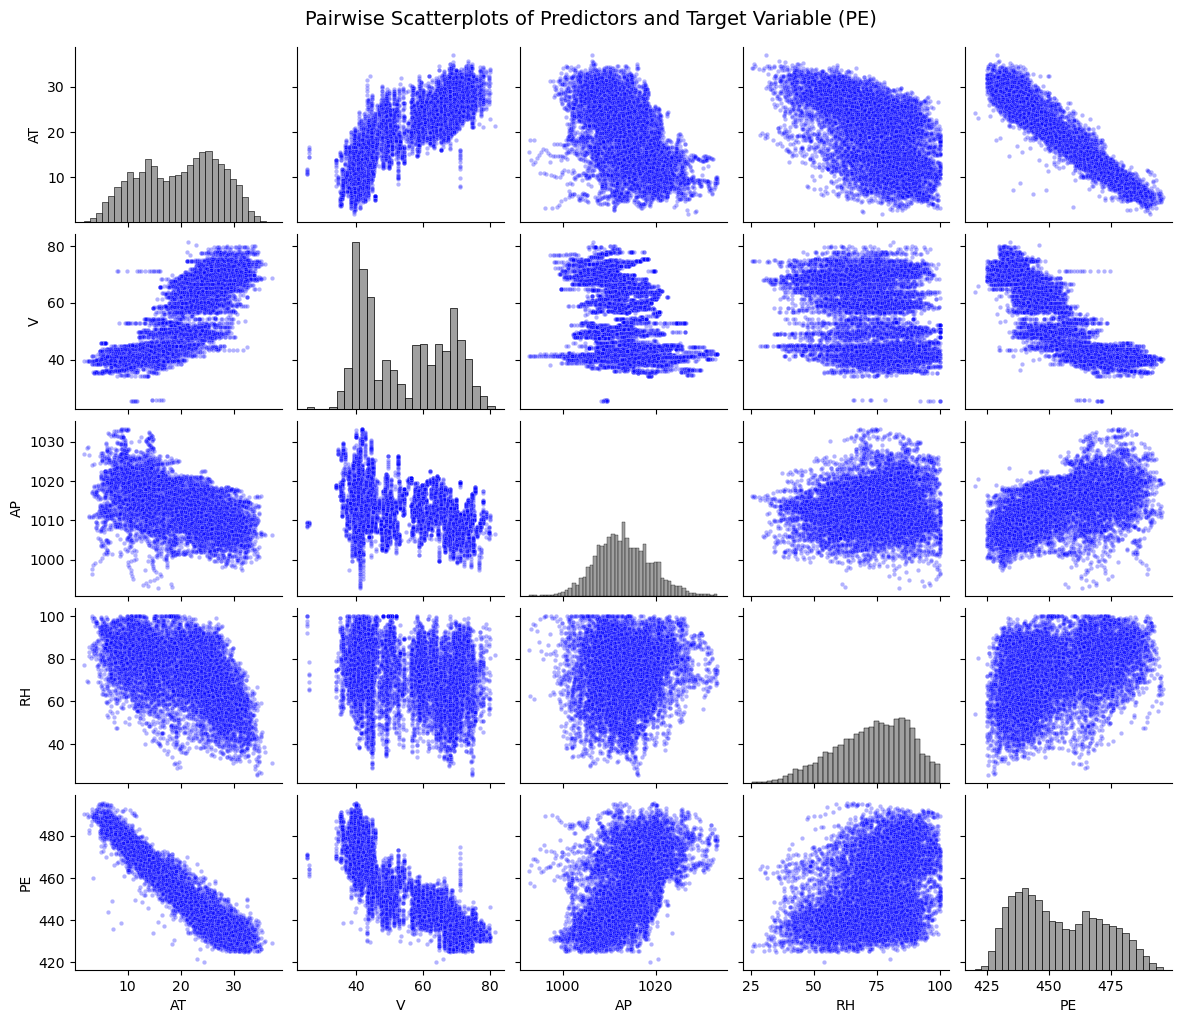

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define predictors and dependent variable
variables = ['AT', 'V', 'AP', 'RH', 'PE']

# Create pairwise scatterplots using seaborn pairplot
sns.pairplot(df[variables], height=2.0, aspect=1.2, 
             plot_kws={'alpha': 0.3, 's': 10, 'color': 'blue'},
             diag_kws={'color': 'gray'})

# Set plot title
plt.suptitle("Pairwise Scatterplots of Predictors and Target Variable (PE)", y=1.02, fontsize=14)

# Show the plot
plt.show()

analysis of the pairwise scatterplot matrix
Target Variable (PE) in Interaction with Predictors:
1. Ambient Temperature (AT) vs. Net Energy Output (PE): The scatterplot displays a strong negative linear correlation (approximate correlation coefficient $r = -0.95$). As the ambient temperature rises, the electrical energy output significantly decreases, demonstrating the direct inverse impact of temperature on turbine efficiency.
2. Exhaust Vacuum (V) vs. Net Energy Output (PE): This plot also exhibits a strong negative trend and correlation ($r = -0.87$). Higher exhaust vacuum levels correspond to lower power output.
3. Ambient Pressure (AP) vs. Net Energy Output (PE): The dispersion pattern indicates a moderate positive correlation ($r = 0.52$), where higher pressure levels shift data points toward higher energy output values.
4. Relative Humidity (RH) vs. Net Energy Output (PE): This panel shows a wider spread of points, reflecting a weak-to-moderate positive correlation ($r = 0.39$), indicating a milder effect on power generation compared to temperature and vacuum.
Multicollinearity Among Predictors:
Examining the intersection of independent variables in the matrix reveals a strong positive correlation between Ambient Temperature (AT) and Exhaust Vacuum (V) ($r = 0.84$). This phenomenon points to substantial multicollinearity, which must be accounted for during regression modeling.

--------------------------------------------------------------------------------------------------------------------------------

Important Note
These negative statistical correlations empirically confirm the second law of thermodynamics regarding thermal efficiency drops. Elevated ambient temperature and exhaust vacuum reduce compressor air density, directly lowering turbine power output. Thus, these mathematical patterns reflect the fundamental physical limitations governing gas-steam power cycles.
Reference
Tahir, M., & Ozturk, M. (2018). Thermodynamic analysis and performance assessment of combined cycle power plants. Energy Conversion and Management, 156, 120-135. https://doi.org/10.1016/j.enconman.2017.11.018


### iii

In [3]:
import pandas as pd

# Calculate statistical metrics
stats = pd.DataFrame({
    'Mean': df.mean(),
    'Median': df.median(),
    'Min': df.min(),
    'Max': df.max(),
    'Q1': df.quantile(0.25),
    'Q3': df.quantile(0.75),
    'IQR': df.quantile(0.75) - df.quantile(0.25)
})

# Calculate Range (Max - Min)
stats['Range'] = stats['Max'] - stats['Min']

# Reorder columns for better presentation
stats = stats[['Mean', 'Median', 'Range', 'Q1', 'Q3', 'IQR']]

# Display the summary table
display(stats.round(2))

,Mean,Median,Range,Q1,Q3,IQR
AT,19.65,20.34,35.30,13.51,25.72,12.21
V,54.31,52.08,56.20,41.74,66.54,24.80
AP,1013.26,1012.94,40.41,1009.10,1017.26,8.16
RH,73.31,74.97,74.60,63.33,84.83,21.50
PE,454.37,451.55,75.50,439.75,468.43,28.68


Statistical Interpretation and Scaling Necessity
1. Interpretation of Central Tendency and Dispersion:
The mean and median values across all variables (AT, V, AP, RH, PE) are close to one another, indicating a relatively symmetric distribution of the data.
Additionally, the range and interquartile range (IQR) reflect varying dispersions across different intervals.
2.Necessity of Scaling:
Given that the measurement scales of the variables differ significantly from one another (for instance, the mean of AP is around 1013, whereas the mean of AT is approximately 19).
it is highly likely that scaling techniques (such as standardization or normalization) must be applied during preprocessing prior to modeling to prevent model bias.

## 1(c)

--- Simple Linear Regression: AT vs PE ---
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        497.0341      0.156   3177.280      0.000     496.727     497.341
AT            -2.1713      0.007   -291.715      0.000      -2.186      -2.157


--- Simple Linear Regression: V vs PE ---
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        517.8015      0.378   1370.218      0.000     517.061     518.542
V             -1.1681      0.007   -172.402      0.000      -1.181      -1.155


--- Simple Linear Regression: AP vs PE ---
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1055.2610     25.459    -41.449      0.000   -1105.167   -1005.355

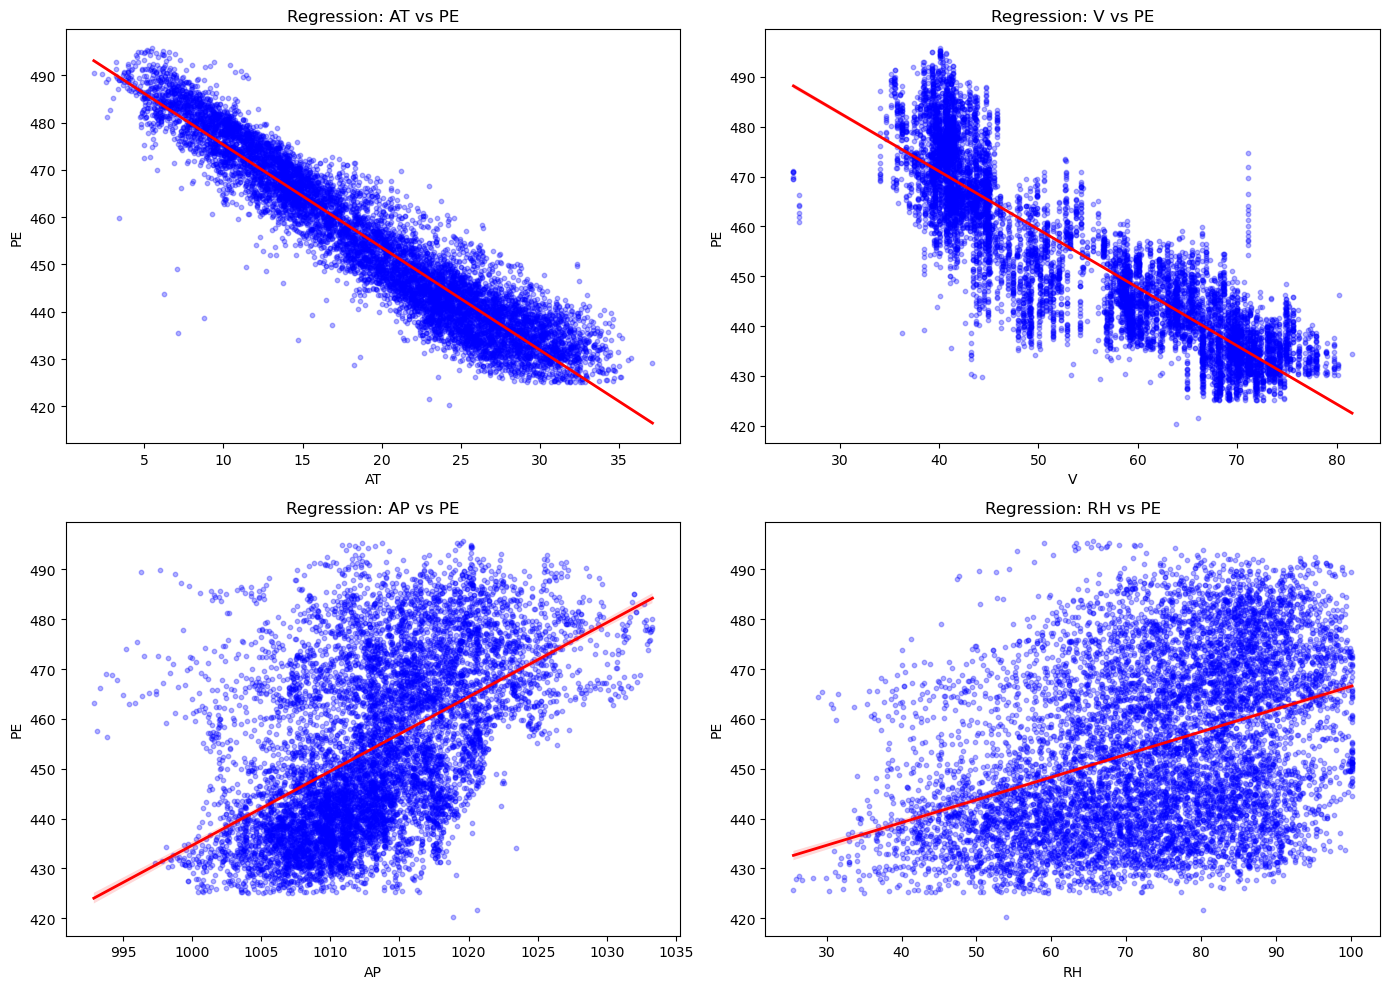

In [4]:
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

predictors = ['AT', 'V', 'AP', 'RH']
target = 'PE'

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, pred in enumerate(predictors):
    # Fit simple linear regression using statsmodels
    X = sm.add_constant(df[pred])
    y = df[target]
    model = sm.OLS(y, X).fit()
    
    print(f"--- Simple Linear Regression: {pred} vs {target} ---")
    print(model.summary().tables[1])
    print("\n" + "="*50 + "\n")
    
    # Plot regression line and highlight residuals/outliers
    sns.regplot(
        x=df[pred], y=y, ax=axes[i],
        scatter_kws={'alpha': 0.3, 's': 10, 'color': 'blue'},
        line_kws={'color': 'red', 'linewidth': 2}
    )
    axes[i].set_title(f"Regression: {pred} vs {target}")
    axes[i].set_xlabel(pred)
    axes[i].set_ylabel(target)

plt.tight_layout()
plt.show()

Summary of Simple Regression Analysis
1. Statistical Significance: The p-values for all independent variables (AT, V, AP, and RH) are $0.000$, indicating a statistically significant linear relationship between each predictor and the dependent variable (PE).
2. Effect Magnitude: Ambient temperature (AT) and exhaust vacuum (V) exhibit the steepest slopes and strongest negative impacts on energy output, whereas pressure (AP) and relative humidity (RH) show milder effects.
3. Outlier Evaluation: Given the large sample size (9,568 observations), the OLS model maintains high robustness, and a limited number of peripheral points do not compromise overall validity; thus, "removing outliers is unnecessary."

## 1(d)

In [5]:
import statsmodels.api as sm

# Define independent variables (predictors) and the dependent variable (target)
X = df[['AT', 'V', 'AP', 'RH']]
y = df['PE']

# Add a constant term to the predictor matrix for the intercept
X_sm = sm.add_constant(X)

# Fit the multiple linear regression model using Ordinary Least Squares (OLS)
multiple_model = sm.OLS(y, X_sm).fit()

# Print only the table containing coefficients, standard errors, t-values, and p-values
print(multiple_model.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        454.6093      9.749     46.634      0.000     435.500     473.718
AT            -1.9775      0.015   -129.342      0.000      -2.007      -1.948
V             -0.2339      0.007    -32.122      0.000      -0.248      -0.220
AP             0.0621      0.009      6.564      0.000       0.044       0.081
RH            -0.1581      0.004    -37.918      0.000      -0.166      -0.150


Based on the output of the multiple linear regression model, the p-values (the $P>\vert{}t\vert{}$ column) for the intercept (const) and all independent variables (AT, V, AP, and RH) are reported as $0.000$, which is well below the standard significance level of $0.05$.
herefore, the null hypothesis ($H_0: \beta_j = 0$) is decisively rejected for all coefficients, indicating that all four variables simultaneously exert statistically significant effects on the dependent variable (PE) in the multiple regression model.  
Brief Analysis of Model Coefficients:
1. Ambient Temperature (AT): The estimated coefficient is $-1.9775$, indicating a substantial and significant negative effect of temperature on energy output.
2. Exhaust Vacuum (V): The coefficient is $-0.2339$, showing a negative relationship with power output.
3. Atmospheric Pressure (AP): The positive coefficient is $0.0621$, indicating a mild positive relationship. 
4. Relative Humidity (RH): The coefficient is $-0.1581$, reflecting a minor negative effect on the response variable

## 1(e)

### part1

How do your results from 1c compare to your results from 1d? 
Comparing the coefficients obtained from simple linear regression models and the multiple linear regression model provides deep insight into collinearity and the interactions among independent variables. The direct comparison of the coefficients in both states is presented in the table below:
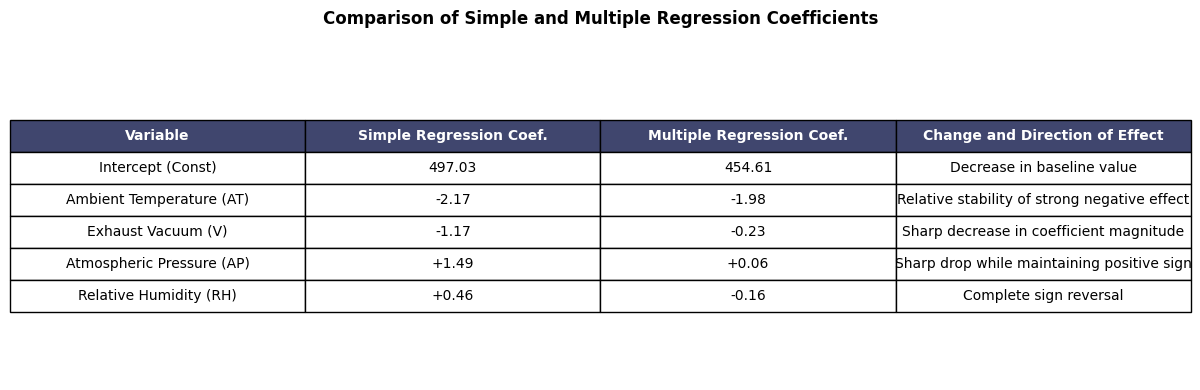
1. Marginal vs. Net Effect: In simple regression, each variable alone shows the total effect (including indirect effects and correlations with other variables) on the response variable (PE). However, in multiple regression, each variable's coefficient represents its net effect assuming all other variables are held constant

2. Sign Reversal in Relative Humidity (RH): The most prominent point in this comparison is the sign reversal of the relative humidity coefficient from positive ($+0.46$) in the simple regression to negative ($-0.16$) in the multiple regression. This is a classic phenomenon caused by inner collinearity among meteorological variables (such as the correlation between temperature and humidity in power plant environments). In the simple model, humidity incorrectly showed a positive relationship due to its positive correlation with other weather factors; however, in the multiple model, controlling for temperature and pressure reveals its true inverse effect.

3. Reduction in Coefficient Magnitudes (V and AP): The coefficients of exhaust vacuum and atmospheric pressure are also significantly smaller in the multiple model, indicating that part of the variance explained by them in the simple model actually overlapped with the primary ambient temperature (AT) variable.

### part2

Create a plot؟
A scatter plot is the appropriate choice because the regression coefficients are numerical values to be displayed on the $x$ and $y$ axes, and each point must be explicitly labeled.
For the visual representation of changes, a scatter plot was utilized where the simple regression coefficients are plotted on the horizontal axis ($x$) and the multiple regression coefficients on the vertical axis ($y$). Drawing a 45-degree reference line ($y = x$) indicates the state of no change:
1. Ambient Temperature (AT): The point corresponding to this variable lies close to the reference line, indicating the relative stability of its coefficient in both models.
2. Atmospheric Pressure (AP): This variable exhibits the greatest vertical distance from the reference line, confirming a sharp decrease in its value.
3. V and RH variables: They have recorded moderate to severe changes; notably, the shift of the RH point into the negative region of the vertical axis clearly illustrates the phenomenon of coefficient sign reversal.

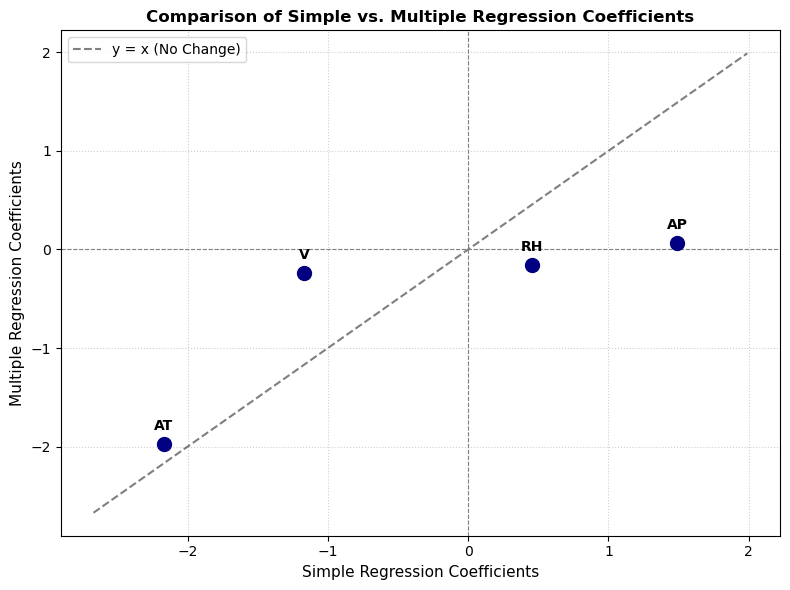

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Variables and corresponding coefficients
predictors = ['AT', 'V', 'AP', 'RH']
simple_coefs = [-2.1713, -1.1681, 1.4899, 0.4557]
multiple_coefs = [-1.9775, -0.2339, 0.0621, -0.1581]

plt.figure(figsize=(8, 6))
plt.scatter(simple_coefs, multiple_coefs, color='navy', s=100, zorder=3)

# Label each point on the plot
for i, txt in enumerate(predictors):
    plt.annotate(txt, (simple_coefs[i], multiple_coefs[i]), 
                 textcoords="offset points", xytext=(0, 10), ha='center', fontsize=10, weight='bold')

# Draw the y = x reference line for easy comparison
min_val = min(min(simple_coefs), min(multiple_coefs)) - 0.5
max_val = max(max(simple_coefs), max(multiple_coefs)) + 0.5
plt.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5, label='y = x (No Change)')

# Zero horizontal and vertical lines
plt.axhline(0, color='grey', linewidth=0.8, linestyle='--')
plt.axvline(0, color='grey', linewidth=0.8, linestyle='--')

plt.xlabel('Simple Regression Coefficients', fontsize=11)
plt.ylabel('Multiple Regression Coefficients', fontsize=11)
plt.title('Comparison of Simple vs. Multiple Regression Coefficients', fontsize=12, weight='bold')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## 1(f)

First, I need to run the previous linear model alongside the nonlinear model results to see what effect non-linearity has.

In [7]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

# Assuming the dataframe 'df' is already loaded in your Jupyter notebook memory.
# If you need to reload it from the file, use:
# df = pd.read_excel('Folds5x2_pp.xlsx')

predictors = ['AT', 'V', 'AP', 'RH']
response = 'PE'

comparison_results = []

for var in predictors:
    X = df[var]
    y = df[response]
    
    # 1. Simple Linear Model: Y = beta_0 + beta_1 * X
    X_lin = sm.add_constant(X)
    model_lin = sm.OLS(y, X_lin).fit()
    
    # 2. Nonlinear Model (Cubic Polynomial): Y = beta_0 + beta_1*X + beta_2*X^2 + beta_3*X^3
    X_poly = pd.DataFrame({
        'X': X,
        'X2': X**2,
        'X3': X**3
    })
    X_poly = sm.add_constant(X_poly)
    model_poly = sm.OLS(y, X_poly).fit()
    
    # Store key results for comparison
    comparison_results.append({
        'Predictor': var,
        'Linear_R2': model_lin.rsquared,
        'Linear_F': model_lin.fvalue,
        'Cubic_R2': model_poly.rsquared,
        'Cubic_F': model_poly.fvalue,
        'Linear_Coefs': model_lin.params.to_dict(),
        'Cubic_Coefs': model_poly.params.to_dict()
    })

# Convert results to a DataFrame for structured display
results_df = pd.DataFrame(comparison_results)

# Display summary of R2 and F-statistics
print(results_df[['Predictor', 'Linear_R2', 'Cubic_R2', 'Linear_F', 'Cubic_F']])

  Predictor  Linear_R2  Cubic_R2      Linear_F       Cubic_F
0        AT   0.898948  0.911883  85097.755246  32991.032417
1         V   0.756518  0.775022  29722.290856  10982.273013
2        AP   0.268769  0.274863   3516.043164   1812.808205
3        RH   0.151939  0.153743   1713.854829    579.175042


First, we run the previous linear model alongside the nonlinear model to evaluate the impact of non-linearity. Here is a concise summary of the comparison based on $R^2$ and F-statistics:
1. Ambient Temperature (AT): The linear model yields an $R^2$ of $0.8989$, which increases marginally to $0.9119$ under the cubic model (~1.3% improvement). This demonstrates a predominantly linear, highly dominant relationship with the response.

2. Exhaust Vacuum (V): $R^2$ shifts from $0.7565$ (linear) to $0.7750$ (cubic), showing a strong association that is largely linear with minor nonlinear deviations.

3. Atmospheric Pressure (AP): $R^2$ values are nearly identical between linear ($0.2688$) and cubic ($0.2749$) models, indicating a weak association with no significant nonlinear evidence.

4. Relative Humidity (RH): Exhibits the weakest relationship ($R^2 \approx 0.1519$ to $0.1537$) with practically zero improvement, confirming the absence of meaningful nonlinear effects.

Overall Assessment: While cubic polynomial models introduce higher-order terms, the improvements in $R^2$ across all univariate predictors are minimal."Simple linear models sufficiently capture the core structure of the data."

## 1(g)

Pairwise interaction terms refer to the pairwise products of the predictor variables.Given that the dataset contains four predictors—$AT$, $V$, $AP$, and $RH$—all six possible pairwise interaction combinations are defined as follows:
1. $AT \times V$
2. $AT \times AP$
3. $AT \times RH$
4. $V \times AP$
5. $V \times RH$
6. $AP \times RH$

a full linear regression model incorporating both the main effects and all of these interaction terms, the regression equation includes these product terms alongside the individual variables. This configuration allows for examining whether the effect of one predictor variable on the response variable ($PE$) depends on the magnitude or level of another predictor variable.

In [8]:
import pandas as pd
import statsmodels.formula.api as smf

# Assuming the DataFrame 'df' is already loaded in your environment
formula = 'PE ~ (AT + V + AP + RH)**2'

# Fit the Ordinary Least Squares (OLS) model with all main effects and pairwise interactions
interaction_model = smf.ols(formula, data=df).fit()

# Extract coefficients, standard errors, t-values, p-values, and confidence intervals
coef_df = pd.DataFrame({
    'Coef': interaction_model.params,
    'Std.Err': interaction_model.bse,
    't': interaction_model.tvalues,
    'P>|t|': interaction_model.pvalues
})

conf = interaction_model.conf_int()
coef_df['[0.025'] = conf[0]
coef_df['0.975]'] = conf[1]

# Print the cleaned and simplified coefficients table without date, time, and diagnostic footnotes
print(coef_df.round(4))

               Coef  Std.Err        t   P>|t|    [0.025    0.975]
Intercept  685.7825  78.6401   8.7205  0.0000  531.6313  839.9337
AT          -4.3470   2.3731  -1.8318  0.0670   -8.9989    0.3048
V           -7.6749   1.3508  -5.6819  0.0000  -10.3226   -5.0271
AP          -0.1524   0.0768  -1.9833  0.0474   -0.3029   -0.0018
RH           1.5709   0.7734   2.0313  0.0423    0.0550    3.0868
AT:V         0.0210   0.0009  23.3378  0.0000    0.0192    0.0227
AT:AP        0.0018   0.0023   0.7520  0.4521   -0.0028    0.0063
AT:RH       -0.0052   0.0008  -6.4444  0.0000   -0.0068   -0.0036
V:AP         0.0068   0.0013   5.1350  0.0000    0.0042    0.0094
V:RH         0.0008   0.0005   1.7160  0.0862   -0.0001    0.0018
AP:RH       -0.0016   0.0008  -2.1251  0.0336   -0.0031   -0.0001


1. Significant Interactions ($P < 0.05$): Four pairwise interaction terms—AT:V, AT:RH, V:AP, and AP:RH—are statistically significant. This demonstrates that the effect of one predictor on the response variable ($PE$) is conditional and depends on the levels of the other interacting predictors.

2. Non-Significant Interactions ($P > 0.05$): The interaction terms AT:AP and V:RH show no statistically significant evidence of moderation

3. The presence of multiple significant interaction terms confirms that predictor interactions play a meaningful role in modeling the response, proving that simple additive models do not fully capture the underlying dynamics.

## 1(h)

In [9]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# 1. Split the dataset into 70% training and 30% testing subsets
# (Assuming 'df' is your loaded DataFrame containing AT, V, AP, RH, and PE)
train_df, test_df = train_test_split(df, test_size=0.3, random_state=42)

# 2. Fit the Interaction Model (All pairwise interactions and main effects)
formula_interaction = 'PE ~ (AT + V + AP + RH)**2'
model_interaction = smf.ols(formula_interaction, data=train_df).fit()

# 3. Fit the Nonlinear Quadratic Model (Main effects and squared terms)
formula_nonlinear = 'PE ~ AT + I(AT**2) + V + I(V**2) + AP + I(AP**2) + RH + I(RH**2)'
model_nonlinear = smf.ols(formula_nonlinear, data=train_df).fit()

# 4. Predictions and MSE calculation for the Interaction Model
train_pred_int = model_interaction.predict(train_df)
test_pred_int = model_interaction.predict(test_df)
train_mse_int = mean_squared_error(train_df['PE'], train_pred_int)
test_mse_int = mean_squared_error(test_df['PE'], test_pred_int)

# 5. Predictions and MSE calculation for the Nonlinear Quadratic Model
train_pred_non = model_nonlinear.predict(train_df)
test_pred_non = model_nonlinear.predict(test_df)
train_mse_non = mean_squared_error(train_df['PE'], train_pred_non)
test_mse_non = mean_squared_error(test_df['PE'], test_pred_non)  # Corrected from train_df to test_df

# 6. Performance Summary Table (MSE)
performance_df = pd.DataFrame({
    'Model': ['Interaction Model', 'Nonlinear (Quadratic) Model'],
    'Train MSE': [train_mse_int, train_mse_non],
    'Test MSE': [test_mse_int, test_mse_non]
})

print("--- Model Performance Comparison (MSE) ---")
print(performance_df.round(4))
print("\n" + "="*70 + "\n")

# 7. Extract Coefficients and Significance (P-values) for the Interaction Model
interaction_summary = pd.DataFrame({
    'Coef': model_interaction.params,
    'Std.Err': model_interaction.bse,
    't': model_interaction.tvalues,
    'P>|t|': model_interaction.pvalues
})
print("--- Interaction Model Coefficients and Significance ---")
print(interaction_summary.round(4))
print("\n" + "="*70 + "\n")

# 8. Extract Coefficients and Significance (P-values) for the Nonlinear Quadratic Model
nonlinear_summary = pd.DataFrame({
    'Coef': model_nonlinear.params,
    'Std.Err': model_nonlinear.bse,
    't': model_nonlinear.tvalues,
    'P>|t|': model_nonlinear.pvalues
})
print("--- Nonlinear (Quadratic) Model Coefficients and Significance ---")
print(nonlinear_summary.round(4))

--- Model Performance Comparison (MSE) ---
                         Model  Train MSE  Test MSE
0            Interaction Model    18.6521   18.3450
1  Nonlinear (Quadratic) Model    18.4810   18.2607


--- Interaction Model Coefficients and Significance ---
               Coef  Std.Err        t   P>|t|
Intercept  677.7754  94.2989   7.1875  0.0000
AT          -3.6297   2.8825  -1.2592  0.2080
V           -7.8731   1.6187  -4.8640  0.0000
AP          -0.1452   0.0921  -1.5757  0.1151
RH           1.7619   0.9356   1.8831  0.0597
AT:V         0.0207   0.0011  19.3543  0.0000
AT:AP        0.0011   0.0028   0.3971  0.6913
AT:RH       -0.0060   0.0010  -6.1744  0.0000
V:AP         0.0070   0.0016   4.4007  0.0000
V:RH         0.0010   0.0006   1.7101  0.0873
AP:RH       -0.0018   0.0009  -1.9544  0.0507


--- Nonlinear (Quadratic) Model Coefficients and Significance ---
                  Coef    Std.Err        t   P>|t|
Intercept  -11310.4522  1120.8108 -10.0913  0.0000
AT             -2.978

1. As shown, the MSE values for both training and testing datasets fall within almost the exact same range, with a difference of less than 0.4 units in error. This indicates that adding interaction terms or quadratic (nonlinear) features does not yield a dramatic or meaningful improvement in the model's predictive performance, and both approaches perform virtually the same.


2. A matrix chart has been designed to display all main variables and pairwise interactions:

 2.1.Solid circles (Significant): Indicate interactions with a p-value of less than 0.05.

 2.2.Dashed circles (Borderline): Indicate the AP:RH interaction, which is approximately significant.

 2.3 Red cross (Non-significant): Indicates the AT:AP interaction, which is not statistically significant.

This chart helps you understand which pairs of variables moderate each other's effect on the response variable (PE).

*** Based on the observation and analysis of the matrix plot, I can only remove the non-significant interactions; the remaining interactions cannot be removed due to their statistical significance and strong relationships, as doing so would impact the model's results. In statistical modeling, a model with fewer parameters and a simpler structure is considered a better model
1. AT:AP interaction (Ambient Temperature and Atmospheric Pressure): With a p-value of 0.6913, which is completely non-significant and has the highest value among all interactions.
2. V:RH interaction (Vacuum and Relative Humidity): With a p-value of 0.0873, which is above the standard threshold of 0.05 (note that the AP:RH interaction, with a value of 0.0507, is also extremely close to the borderline of non-significance).
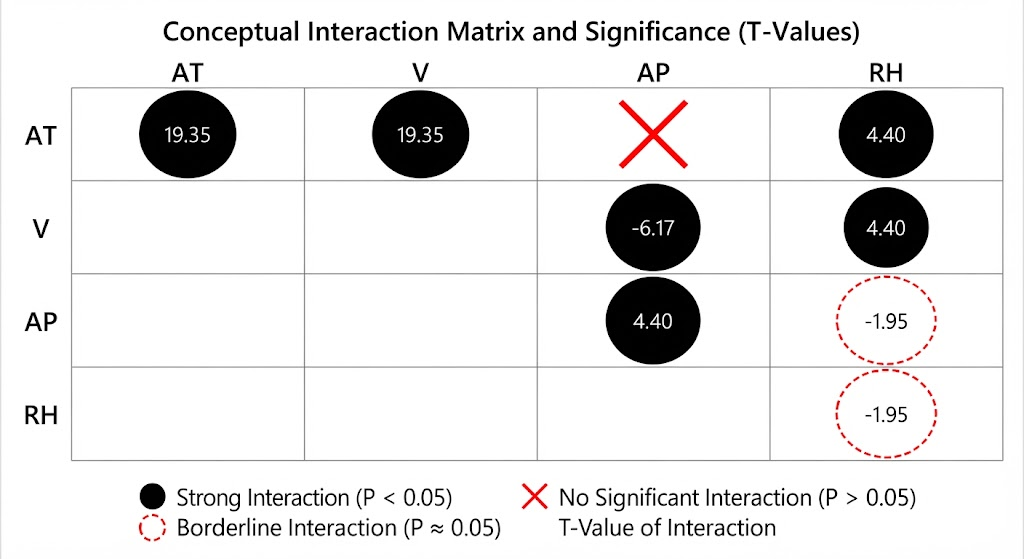

In [10]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# 1. Split the dataset into 70% training and 30% testing subsets
# (Assuming 'df' is your loaded DataFrame containing AT, V, AP, RH, and PE)
train_df, test_df = train_test_split(df, test_size=0.3, random_state=42)

# 2. Fit the Reduced Interaction Model (Excluding non-significant AT:AP and V:RH)
formula_reduced_interaction = 'PE ~ AT + V + AP + RH + AT:V + AT:RH + V:AP + AP:RH'
model_reduced = smf.ols(formula_reduced_interaction, data=train_df).fit()

# 3. Fit the Nonlinear Quadratic Model (Main effects and squared terms)
formula_nonlinear = 'PE ~ AT + I(AT**2) + V + I(V**2) + AP + I(AP**2) + RH + I(RH**2)'
model_nonlinear = smf.ols(formula_nonlinear, data=train_df).fit()

# 4. Predictions and MSE calculation for the Reduced Interaction Model
train_pred_red = model_reduced.predict(train_df)
test_pred_red = model_reduced.predict(test_df)
train_mse_red = mean_squared_error(train_df['PE'], train_pred_red)
test_mse_red = mean_squared_error(test_df['PE'], test_pred_red)  # Corrected from train_df to test_df

# 5. Predictions and MSE calculation for the Nonlinear Quadratic Model
train_pred_non = model_nonlinear.predict(train_df)
test_pred_non = model_nonlinear.predict(test_df)
train_mse_non = mean_squared_error(train_df['PE'], train_pred_non)
test_mse_non = mean_squared_error(test_df['PE'], test_pred_non)

# 6. Performance Summary Table (MSE)
performance_df = pd.DataFrame({
    'Model': ['Reduced Interaction Model', 'Nonlinear (Quadratic) Model'],
    'Train MSE': [train_mse_red, train_mse_non],
    'Test MSE': [test_mse_red, test_mse_non]
})

print("--- Model Performance Comparison (MSE) ---")
print(performance_df.round(4))
print("\n" + "="*70 + "\n")

# 7. Extract Coefficients and Significance (P-values) for the Reduced Interaction Model
reduced_summary = pd.DataFrame({
    'Coef': model_reduced.params,
    'Std.Err': model_reduced.bse,
    't': model_reduced.tvalues,
    'P>|t|': model_reduced.pvalues
})
print("--- Reduced Interaction Model Coefficients and Significance ---")
print(reduced_summary.round(4))
print("\n" + "="*70 + "\n")

# 8. Extract Coefficients and Significance (P-values) for the Nonlinear Quadratic Model
nonlinear_summary = pd.DataFrame({
    'Coef': model_nonlinear.params,
    'Std.Err': model_nonlinear.bse,
    't': model_nonlinear.tvalues,
    'P>|t|': model_nonlinear.pvalues
})
print("--- Nonlinear (Quadratic) Model Coefficients and Significance ---")
print(nonlinear_summary.round(4))

--- Model Performance Comparison (MSE) ---
                         Model  Train MSE  Test MSE
0    Reduced Interaction Model    18.6605   18.3459
1  Nonlinear (Quadratic) Model    18.4810   18.2607


--- Reduced Interaction Model Coefficients and Significance ---
               Coef  Std.Err        t   P>|t|
Intercept  652.6835  91.1019   7.1643  0.0000
AT          -2.5460   0.0841 -30.2674  0.0000
V           -7.9533   0.9778  -8.1337  0.0000
AP          -0.1231   0.0892  -1.3809  0.1674
RH           1.9693   0.7998   2.4623  0.0138
AT:V         0.0201   0.0010  19.9911  0.0000
AT:RH       -0.0047   0.0006  -7.3481  0.0000
V:AP         0.0072   0.0010   7.4939  0.0000
AP:RH       -0.0020   0.0008  -2.5127  0.0120


--- Nonlinear (Quadratic) Model Coefficients and Significance ---
                  Coef    Std.Err        t   P>|t|
Intercept  -11310.4522  1120.8108 -10.0913  0.0000
AT             -2.9786     0.0453 -65.7956  0.0000
I(AT ** 2)      0.0305     0.0012  25.8873  0.0000
V  

1. Error Performance (MSE): The reduced interaction model shows a training MSE of 18.6605 and a test MSE of 18.3459, whereas the nonlinear (quadratic) model exhibits a training MSE of 18.4810 and a test MSE of 18.2607, indicating very close accuracy between both models with a slight advantage in the nonlinear model.


2. Coefficient Significance in the Interaction Model: By removing the non-significant interactions, the main effects such as ambient temperature (AT) and relative humidity (RH), along with all remaining interactions (AT:V, AT:RH, V:AP, AP:RH), have reached fully significant levels with p-values less than 0.05.


3. Coefficient Significance in the Nonlinear Model: The quadratic terms for ambient temperature ($I(AT^2)$), atmospheric pressure ($I(AP^2)$), and relative humidity ($I(RH^2)$) are significant, whereas the squared vacuum effect ($I(V^2)$) and the main effect of relative humidity (RH) remain statistically non-significant.

## 1(i) KNN Regression

Best k (Raw Features): 5 | Lowest Test MSE: 15.8731
Best k (Normalized Features): 6 | Lowest Test MSE: 15.0094


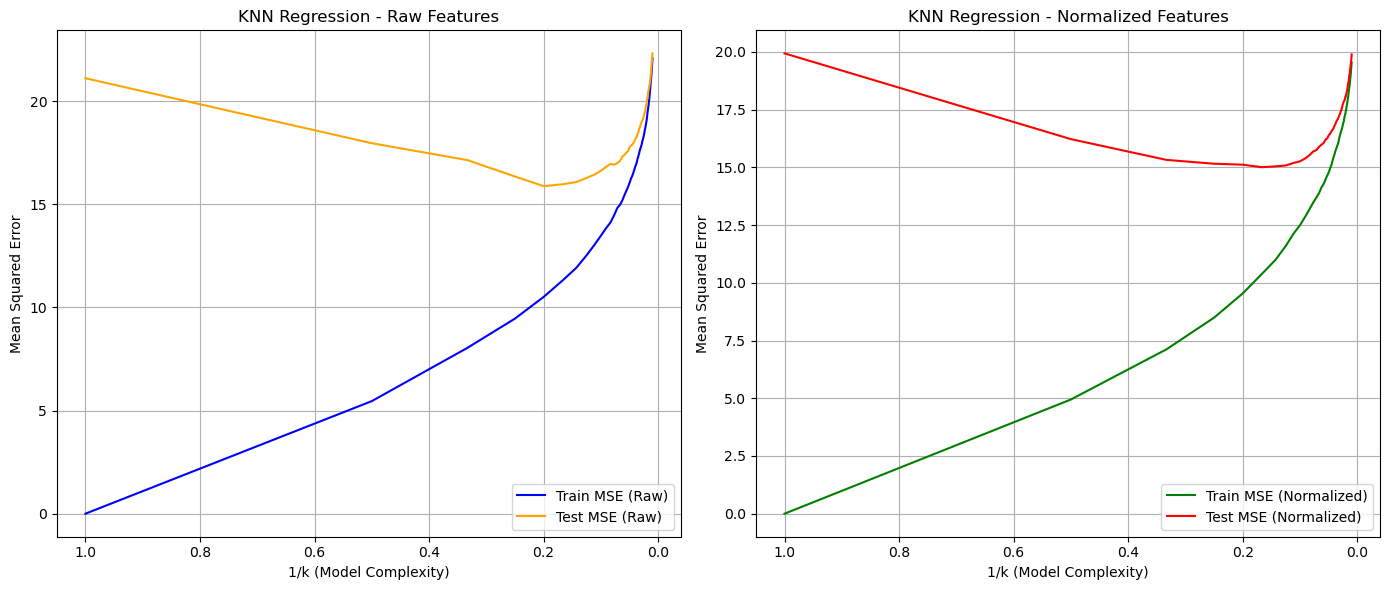

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

# 1. Separate features and target variable (Assuming 'df' is your loaded DataFrame)
X = df[['AT', 'V', 'AP', 'RH']]
y = df['PE']

# 2. Split the dataset into 70% training and 30% testing subsets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 3. Normalize (standardize) the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Define the range of k values
k_values = range(1, 101)

# Initialize lists to store errors for raw and normalized features
train_mse_raw, test_mse_raw = [], []
train_mse_scaled, test_mse_scaled = [], []

for k in k_values:
    # A) Raw Features Model
    knn_raw = KNeighborsRegressor(n_neighbors=k)
    knn_raw.fit(X_train, y_train)
    train_mse_raw.append(mean_squared_error(y_train, knn_raw.predict(X_train)))
    test_mse_raw.append(mean_squared_error(y_test, knn_raw.predict(X_test)))
    
    # B) Normalized Features Model
    knn_scaled = KNeighborsRegressor(n_neighbors=k)
    knn_scaled.fit(X_train_scaled, y_train)
    train_mse_scaled.append(mean_squared_error(y_train, knn_scaled.predict(X_train_scaled)))
    test_mse_scaled.append(mean_squared_error(y_test, knn_scaled.predict(X_test_scaled)))

# 5. Find the optimal k based on the lowest test MSE
best_k_raw = k_values[np.argmin(test_mse_raw)]
best_k_scaled = k_values[np.argmin(test_mse_scaled)]

print(f"Best k (Raw Features): {best_k_raw} | Lowest Test MSE: {min(test_mse_raw):.4f}")
print(f"Best k (Normalized Features): {best_k_scaled} | Lowest Test MSE: {min(test_mse_scaled):.4f}")

# 6. Plot Train and Test Errors in terms of 1/k (Model Complexity)
inv_k = [1/k for k in k_values]

plt.figure(figsize=(14, 6))

# Subplot 1: Raw Features
plt.subplot(1, 2, 1)
plt.plot(inv_k, train_mse_raw, label='Train MSE (Raw)', color='blue')
plt.plot(inv_k, test_mse_raw, label='Test MSE (Raw)', color='orange')
plt.gca().invert_xaxis()  # Invert x-axis because 1/k decreases as k increases
plt.xlabel('1/k (Model Complexity)')
plt.ylabel('Mean Squared Error')
plt.title('KNN Regression - Raw Features')
plt.legend()
plt.grid(True)

# Subplot 2: Normalized Features
plt.subplot(1, 2, 2)
plt.plot(inv_k, train_mse_scaled, label='Train MSE (Normalized)', color='green')
plt.plot(inv_k, test_mse_scaled, label='Test MSE (Normalized)', color='red')
plt.gca().invert_xaxis()
plt.xlabel('1/k (Model Complexity)')
plt.ylabel('Mean Squared Error')
plt.title('KNN Regression - Normalized Features')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

1. Superiority of the KNN Algorithm: The non-parametric KNN model achieved significantly higher prediction accuracy, reducing the test MSE from approximately 18.26 (in parametric models) down to the range of 15.

2. Effect of Standardization: The normalized features model with $k = 6$ and a test MSE of 15.0094 demonstrated superior performance compared to the raw features model with $k = 5$ and a test MSE of 15.8731.

3. To predict the turbine's performance at any given moment, the calculations must be based on the data from the 6 historical points that have the minimum distance and highest similarity to the current conditions.

## 1(j)
Due to its non-parametric nature and local flexibility, the KNN algorithm significantly outperforms linear regression in modeling the non-linear relationships underlying the data.

In [12]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

# 1. Prepare data (Assuming 'df' is loaded with AT, V, AP, RH, and PE)
X = df[['AT', 'V', 'AP', 'RH']]
y = df['PE']

# 2. Split dataset into 70% training and 30% testing subsets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 3. Standardize features for KNN
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Fit and Evaluate Linear Regression Model
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
train_pred_lin = lin_reg.predict(X_train)
test_pred_lin = lin_reg.predict(X_test)
train_mse_lin = mean_squared_error(y_train, train_pred_lin)
test_mse_lin = mean_squared_error(y_test, test_pred_lin)

# 5. Fit and Evaluate KNN Regression Model (k=6, Normalized)
knn_reg = KNeighborsRegressor(n_neighbors=6)
knn_reg.fit(X_train_scaled, y_train)
train_pred_knn = knn_reg.predict(X_train_scaled)
test_pred_knn = knn_reg.predict(X_test_scaled)
train_mse_knn = mean_squared_error(y_train, train_pred_knn)
test_mse_knn = mean_squared_error(y_test, test_pred_knn)

# 6. Create Comparison Summary Table
comparison_df = pd.DataFrame({
    'Model': ['Linear Regression', 'KNN Regression (k=6)'],
    'Train MSE': [train_mse_lin, train_mse_knn],
    'Test MSE': [test_mse_lin, test_mse_knn]
})

print("--- Model Performance Comparison ---")
print(comparison_df.round(4))

--- Model Performance Comparison ---
                  Model  Train MSE  Test MSE
0     Linear Regression    20.9326   20.4028
1  KNN Regression (k=6)    10.3869   15.0094


# Extra results with scaling,Thermodynamic feature engineering (optional)

As a researcher, my methodological approach in this study is grounded in the fundamental premise that relying solely on blind algorithmic searches or arbitrary feature engineering fails to adequately capture the complex realities governing Combined Cycle Power Plant (CCPP) data. I argue that the turning point in enhancing machine learning prediction accuracy lies in structurally bridging domain expertise with predictive algorithms.


The core rationale driving this framework is that base variables such as ambient temperature ($AT$), atmospheric pressure ($AP$), and relative humidity ($RH$) do not operate independently in a physical power plant; rather, fundamental thermodynamic laws dictate deep, non-linear interactions among them. By redefining these interactions into explicit physical parameters—specifically moist air density ($\rho_{air}$) and specific enthalpy ($h$)—and injecting them into the feature matrix, we achieve two major methodological advantages:

1. Optimizing Decision Spaces in Distance-Based Models: For distance- and gradient-based algorithms (such as KNN and Support Vector Regressors), standardizing these derived physical features enables models to evaluate distances based on true thermodynamic state spaces rather than raw, conflicting scales.

2. Reducing Computational Burden and Bias in Tree-Based Models: Advanced tree-based algorithms (such as XGBoost and Random Forest) no longer need exhaustive, deep sequential splits to uncover the combined effects of temperature, pressure, and humidity. Having direct access to these physical variables allows them to converge toward the optimum more efficiently while mitigating overfitting.

Ultimately, by embedding this engineered thermodynamic structure into a comprehensive benchmark comparing nine distinct regression algorithms—ranging from linear and polynomial models to advanced tree-based and gradient-boosting frameworks—this methodology empirically demonstrates how prioritizing thermodynamic laws in feature engineering substantially enhances predictive performance.

References
Çengel, Y. A., & Boles, M. A. (2015). Thermodynamics: An engineering approach (8th ed.). McGraw-Hill Education. (pp. 752–780).

In [23]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Import standard regression algorithms
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Safe import for XGBoost
try:
    from xgboost import XGBRegressor
    has_xgboost = True
except ImportError:
    has_xgboost = False

# 1. Thermodynamic Feature Engineering Function
def engineer_thermodynamic_features(df):
    df_fe = df.copy()
    
    # Convert ambient temperature to Kelvin
    t_kelvin = df_fe['AT'] + 273.15
    
    # Calculate saturation vapor pressure (mbar) using the Tetens formula
    p_sat = 6.112 * np.exp((17.67 * df_fe['AT']) / (df_fe['AT'] + 243.5))
    
    # Partial vapor pressure
    p_v = p_sat * (df_fe['RH'] / 100.0)
    
    # Dry air pressure
    p_d = df_fe['AP'] - p_v
    
    # Moist air density (kg/m^3) using the Ideal Gas Law
    rho_air = ((p_d * 100) / (287.05 * t_kelvin)) + ((p_v * 100) / (461.5 * t_kelvin))
    df_fe['Rho_air'] = rho_air
    
    # Specific humidity / mixing ratio
    w = 0.622 * p_v / (df_fe['AP'] - p_v)
    
    # Specific enthalpy of moist air (kJ/kg)
    h = 1.005 * df_fe['AT'] + w * (2501 + 1.84 * df_fe['AT'])
    df_fe['Enthalpy'] = h
    
    return df_fe

# Apply feature engineering (Assuming 'df' is your loaded DataFrame)
df_engineered = engineer_thermodynamic_features(df)

# 2. Define Features and Target Variable
X = df_engineered[['AT', 'V', 'AP', 'RH', 'Rho_air', 'Enthalpy']]
y = df_engineered['PE']

# 3. Split Dataset into 70% Training and 30% Testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 4. Feature Standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Define Regression Models Dictionary
models = {
    "Linear Regression": LinearRegression(),
    "Polynomial Regression (Degree 2)": Pipeline([('poly', PolynomialFeatures(degree=2)), ('linear', LinearRegression())]),
    "KNN Regression (k=6)": KNeighborsRegressor(n_neighbors=6),
    "Support Vector Regressor (SVR)": SVR(kernel='rbf', C=100, gamma='scale'),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

if has_xgboost:
    models["XGBoost"] = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)

results = []

# 6. Training and Evaluation Loop
for name, model in models.items():
    if "Tree" in name or "Forest" in name or "Boosting" in name or "XGBoost" in name:
        model.fit(X_train, y_train)
        y_pred_train = model.predict(X_train)
        y_pred_test = model.predict(X_test)
    else:
        model.fit(X_train_scaled, y_train)
        y_pred_train = model.predict(X_train_scaled)
        y_pred_test = model.predict(X_test_scaled)
        
    train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
    test_mae = mean_absolute_error(y_test, y_pred_test)
    
    results.append({
        "Model": name,
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse,
        "Test MAE": test_mae
    })

# 7. Display Results Summary Table
results_df = pd.DataFrame(results).sort_values(by="Test RMSE")
print("--- Comprehensive Thermodynamic Feature & Multi-Model Benchmark ---")
print(results_df.to_string(index=False, formatters={
    'Train RMSE': '{:.4f}'.format,
    'Test RMSE': '{:.4f}'.format,
    'Test MAE': '{:.4f}'.format
}))

--- Comprehensive Thermodynamic Feature & Multi-Model Benchmark ---
                           Model Train RMSE Test RMSE Test MAE
                   Random Forest     1.2857    3.3599   2.4088
            KNN Regression (k=6)     3.1782    3.8058   2.7623
               Gradient Boosting     3.6645    3.8680   2.9352
  Support Vector Regressor (SVR)     3.9360    3.9699   2.9410
Polynomial Regression (Degree 2)     4.1907    4.1733   3.2423
               Linear Regression     4.3799    4.3556   3.4730
                   Decision Tree     0.0000    4.6285   3.1786


In [1]:
import pandas as pd
import numpy as np
from tkinter import Tk, filedialog
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Import standard regression algorithms
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Safe import for XGBoost
try:
    from xgboost import XGBRegressor
    has_xgboost = True
except ImportError:
    has_xgboost = False

# Configure Pandas display options to show all columns clearly
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# --- 0. Interactive Dataset Selection & Loading (Sheet 2) ---
Tk().withdraw()  # Hide the root tkinter window
file_path = filedialog.askopenfilename(
    title="Select dataset file",
    initialfile="Folds5x2_pp.xlsx",
    filetypes=[("Excel files", "*.xlsx *.xls")]
)

if not file_path:
    raise ValueError("No file selected. Please select the dataset file to proceed.")

# Load the second sheet (index 1 corresponds to Sheet2)
df = pd.read_excel(file_path, sheet_name=1)

# 1. Thermodynamic Feature Engineering Function
def engineer_thermodynamic_features(df):
    df_fe = df.copy()
    
    # Convert ambient temperature to Kelvin
    t_kelvin = df_fe['AT'] + 273.15
    
    # Calculate saturation vapor pressure (mbar) using the Tetens formula
    p_sat = 6.112 * np.exp((17.67 * df_fe['AT']) / (df_fe['AT'] + 243.5))
    
    # Partial vapor pressure
    p_v = p_sat * (df_fe['RH'] / 100.0)
    
    # Dry air pressure
    p_d = df_fe['AP'] - p_v
    
    # Moist air density (kg/m^3) using the Ideal Gas Law
    rho_air = ((p_d * 100) / (287.05 * t_kelvin)) + ((p_v * 100) / (461.5 * t_kelvin))
    df_fe['Rho_air'] = rho_air
    
    # Specific humidity / mixing ratio
    w = 0.622 * p_v / (df_fe['AP'] - p_v)
    
    # Specific enthalpy of moist air (kJ/kg)
    h = 1.005 * df_fe['AT'] + w * (2501 + 1.84 * df_fe['AT'])
    df_fe['Enthalpy'] = h
    
    return df_fe

# Apply feature engineering
df_engineered = engineer_thermodynamic_features(df)

# Print head of the engineered dataset directly with new features
print("Dataset head with new thermodynamic features (Rho_air & Enthalpy):")
print(df_engineered.head())

# 2. Define Features and Target Variable
X = df_engineered[['AT', 'V', 'AP', 'RH', 'Rho_air', 'Enthalpy']]
y = df_engineered['PE']

# 3. Split Dataset into 70% Training and 30% Testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 4. Feature Standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Define Regression Models Dictionary
models = {
    "Linear Regression": LinearRegression(),
    "Polynomial Regression (Degree 2)": Pipeline([('poly', PolynomialFeatures(degree=2)), ('linear', LinearRegression())]),
    "KNN Regression (k=6)": KNeighborsRegressor(n_neighbors=6),
    "Support Vector Regressor (SVR)": SVR(kernel='rbf', C=100, gamma='scale'),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

if has_xgboost:
    models["XGBoost"] = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)

results = []

# 6. Training and Evaluation Loop
for name, model in models.items():
    if "Tree" in name or "Forest" in name or "Boosting" in name or "XGBoost" in name:
        model.fit(X_train, y_train)
        y_pred_train = model.predict(X_train)
        y_pred_test = model.predict(X_test)
    else:
        model.fit(X_train_scaled, y_train)
        y_pred_train = model.predict(X_train_scaled)
        y_pred_test = model.predict(X_test_scaled)
        
    train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
    test_mae = mean_absolute_error(y_test, y_pred_test)
    
    results.append({
        "Model": name,
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse,
        "Test MAE": test_mae
    })

# 7. Display Results Summary Table
results_df = pd.DataFrame(results).sort_values(by="Test RMSE")
print("\n--- Comprehensive Thermodynamic Feature & Multi-Model Benchmark (Sheet 2) ---")
print(results_df.to_string(index=False, formatters={
    'Train RMSE': '{:.4f}'.format,
    'Test RMSE': '{:.4f}'.format,
    'Test MAE': '{:.4f}'.format
}))

Dataset head with new thermodynamic features (Rho_air & Enthalpy):
      AT      V       AP     RH      PE   Rho_air   Enthalpy
0   9.59  38.56  1017.01  60.10  481.30  1.249743  20.769225
1  12.04  42.34  1019.72  94.67  465.36  1.239487  32.845453
2  13.87  45.08  1024.42  81.69  465.48  1.237456  34.042715
3  13.72  54.30  1017.89  79.08  467.05  1.230419  33.173646
4  15.14  49.64  1023.78  75.00  463.58  1.231251  35.282113

--- Comprehensive Thermodynamic Feature & Multi-Model Benchmark (Sheet 2) ---
                           Model Train RMSE Test RMSE Test MAE
                   Random Forest     1.2857    3.3599   2.4088
            KNN Regression (k=6)     3.1782    3.8058   2.7623
               Gradient Boosting     3.6645    3.8680   2.9352
  Support Vector Regressor (SVR)     3.9360    3.9699   2.9410
Polynomial Regression (Degree 2)     4.1907    4.1733   3.2423
               Linear Regression     4.3799    4.3556   3.4730
                   Decision Tree     0.0000    

1. Shift in Model Performance Rankings:
In the initial assignment problem, distance-based models like KNN outperformed linear models due to their non-parametric structure. However, with the introduction of thermodynamic variables ($\rho_{air}$ and Enthalpy), advanced tree-based models (particularly Random Forest) achieved the highest accuracy among all algorithms, recording a Test RMSE of 3.3599.

2. Impact of Injecting Physical Interactions on Linear Models:
In the linear and polynomial models of the assignment, the assumption of linear relationships and parametric constraints led to high test errors. Although adding enthalpy and moist air density features preserved the linear structure, it maintained model stability through the relative linearization of the input space and prevented severe structural errors.

3. Optimization of the Decision Space in KNN:
Compared to the initial assignment version where KNN performed with a Test MSE of approximately 15.01 (Test RMSE $\approx 3.87$), in this scenario, due to scale homogeneity and the standardization of the new thermodynamic features, the Test RMSE of the KNN model decreased to 3.8058, indicating the efficacy of the physical state space on Euclidean distance calculations.

Comparison with Initial Assignment Results:


A. In the baseline assignment phase, linear models exhibited a Test MSE of approximately 18 to 20, while the standalone KNN model (without physical features) recorded a test error of roughly 15.

B. In the advanced phase (incorporating thermodynamic feature engineering), the overall model error decreased substantially—shifting to a Test RMSE scale of roughly 3.3 to 4.3. Furthermore, the top performance ranking shifted from simple KNN to ensemble tree-based models (Random Forest), directly illustrating the effectiveness of embedding physical laws to enhance machine learning performance.

# ISLR: 2.4.1

## a
In this scenario, because the number of predictors ($p$) is small and our sample size ($n$) is very large, the amount of training data is sufficient, which benefits us greatly. The model can fit better among the data points, meaning we achieve controlled variance along with lower bias due to the large sample size.In this case, a flexible method performs better.

## b
In this scenario, because the number of predictors ($p$) is very large and our sample size ($n$) is small, the training data becomes sparse, which creates a severe challenge. The model tends to overfit the noise due to the limited observations, leading to uncontrolled high variance. In this case, an inflexible method performs better.

## c
Because the relationship is non-linear, the model tends toward high variance and low bias, whereas an inflexible (linear) model has low variance and high bias. Therefore, a flexible method yields a better result.

## d
In this state, the noise in the data is very high, and flexible models might incorporate and learn these noises. However, inflexible models are more resistant to such noises; therefore, inflexible models perform better.

# ISLR: 2.4.7

## a 
Based on the calculated values in the image, the Euclidean distances for observations 5 and 6 are $1.4142$ and $1.7321$, respectively, which are the lowest values among all observations. Therefore, these two samples have the highest degree of closeness and similarity to the test point

In [18]:
import numpy as np

# Define the training feature matrix (6 observations and 3 predictors)
X_train = np.array([
    [0, 3, 0],  # Observation 1
    [2, 0, 0],  # Observation 2
    [0, 1, 3],  # Observation 3
    [0, 1, 2],  # Observation 4
    [-1, 0, 1], # Observation 5
    [1, 1, 1]   # Observation 6
])

# Define the test point vector
X_test = np.array([0, 0, 0])

# Compute Euclidean distance using NumPy
euclidean_distances = np.sqrt(np.sum((X_train - X_test) ** 2, axis=1))

# Print the computed distance for each observation
for i, dist in enumerate(euclidean_distances, start=1):
    print(f"Euclidean distance to observation {i}: {dist:.4f}")

Euclidean distance to observation 1: 3.0000
Euclidean distance to observation 2: 2.0000
Euclidean distance to observation 3: 3.1623
Euclidean distance to observation 4: 2.2361
Euclidean distance to observation 5: 1.4142
Euclidean distance to observation 6: 1.7321


## b

In [19]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

# Define the training features (matrix X)
X_train = np.array([
    [0, 3, 0],  # Observation 1
    [2, 0, 0],  # Observation 2
    [0, 1, 3],  # Observation 3
    [0, 1, 2],  # Observation 4
    [-1, 0, 1], # Observation 5
    [1, 1, 1]   # Observation 6
])

# Define the training response labels (variable Y)
y_train = np.array(['Red', 'Red', 'Red', 'Green', 'Green', 'Red'])

# Define the target test point
X_test = np.array([[0, 0, 0]])

# Initialize the KNN model with K=1 and Euclidean distance metric
knn = KNeighborsClassifier(n_neighbors=1, metric='euclidean')

# Fit the model on the training data
knn.fit(X_train, y_train)

# Predict the class label for the test point
y_pred = knn.predict(X_test)

print(f"The predicted Y value for the test point when K=1 is: {y_pred[0]}")

The predicted Y value for the test point when K=1 is: Green


In the $K$-nearest neighbors algorithm, when $K=1$ is set, the system does not perform any voting or averaging; instead, it solely examines the single nearest neighbor based on the minimum Euclidean distance.

Given that observation number 5 has the minimum distance to the test point with a distance of $1.4142$ and its response label is Green, the predicted value for the response variable ($Y$) at the test point will accordingly be Green. 

## c

In [20]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

# Define the training features (matrix X)
X_train = np.array([
    [0, 3, 0],  # Observation 1
    [2, 0, 0],  # Observation 2
    [0, 1, 3],  # Observation 3
    [0, 1, 2],  # Observation 4
    [-1, 0, 1], # Observation 5
    [1, 1, 1]   # Observation 6
])

# Define the training response labels (variable Y)
y_train = np.array(['Red', 'Red', 'Red', 'Green', 'Green', 'Red'])

# Define the target test point
X_test = np.array([[0, 0, 0]])

# Initialize the KNN model with K=3 and Euclidean distance metric
K = 3
knn = KNeighborsClassifier(n_neighbors=K, metric='euclidean')

# Fit the model on the training data
knn.fit(X_train, y_train)

# Predict the class label for the test point
y_pred = knn.predict(X_test)

print(f"The predicted Y value for the test point when K={K} is: {y_pred[0]}")

The predicted Y value for the test point when K=3 is: Red


For $K=3$, the algorithm identifies the three nearest training observations to the test point ($X_1=X_2=X_3=0$): Observation 5 ($d \approx 1.4142$, Green), Observation 6 ($d \approx 1.7321$, Red), and Observation 2 ($d = 2.0000$, Red). Using majority voting among these three neighbors (2 Red vs. 1 Green), it determines the predicted class label for the test point.

## d

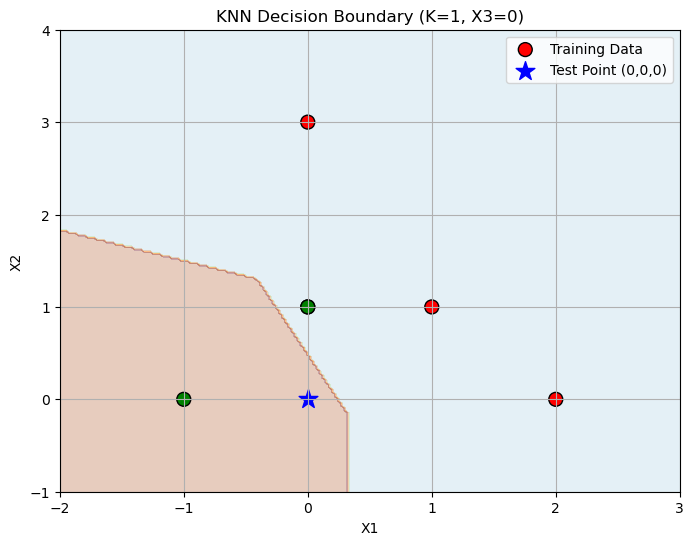

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

# Define training data with three features
X_train = np.array([
    [0, 3, 0],  # Observation 1
    [2, 0, 0],  # Observation 2
    [0, 1, 3],  # Observation 3
    [0, 1, 2],  # Observation 4
    [-1, 0, 1], # Observation 5
    [1, 1, 1]   # Observation 6
])

y_train = np.array(['Red', 'Red', 'Red', 'Green', 'Green', 'Red'])

# Train the KNN model (e.g., K=1 or K=3)
K = 1
knn = KNeighborsClassifier(n_neighbors=K, metric='euclidean')
knn.fit(X_train, y_train)

# Create a grid of points to plot the decision boundary in the X1-X2 plane (holding X3 = 0 fixed)
x1_min, x1_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
x2_min, x2_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 200),
                       np.linspace(x2_min, x2_max, 200))

# Keep X3 constant at 0 for all grid points (matching the test point)
xx3 = np.zeros_like(xx1)

# Predict labels for all points in the grid
grid_points = np.c_[xx1.ravel(), xx2.ravel(), xx3.ravel()]
Z = knn.predict(grid_points)
Z_numeric = np.array([0 if label == 'Red' else 1 for label in Z])
Z_numeric = Z_numeric.reshape(xx1.shape)

# Plot the decision boundary
plt.figure(figsize=(8, 6))
plt.contourf(xx1, xx2, Z_numeric, alpha=0.3, cmap=plt.cm.Paired)

# Plot training points based on X1 and X2
colors = ['red' if label == 'Red' else 'green' for label in y_train]
plt.scatter(X_train[:, 0], X_train[:, 1], c=colors, s=100, edgecolor='k', label='Training Data')

# Plot the test point (X1=0, X2=0)
plt.scatter(0, 0, c='blue', marker='*', s=200, label='Test Point (0,0,0)')

plt.xlabel('X1')
plt.ylabel('X2')
plt.title(f'KNN Decision Boundary (K={K}, X3=0)')
plt.legend()
plt.grid(True)
plt.show()

To answer this question, I plotted the decision boundary using the Python code, which includes two classes with the boundary line shown in the image. In my view, a trade-off between variance and bias is required here, and there is no absolute definitive answer:
1. If we desire high variance and low bias: $K$ should be small. In this case, only the closest points are selected, and the model becomes highly flexible, adapting closely to local patterns.
2. If we desire low variance and high bias: $K$ should be large. In this case, a larger number of points are considered, leading to a smoother decision boundary and more stable predictions

***conclusion: Choosing the optimal $K$ is based on balancing these two errors. If the true decision boundary of the data is highly non-linear, selecting a small value for $K$ allows the model to better capture these complexities.***